# Model Comparison & Actuarial Metrics (Double Lift & Calibration)

Actuarial evaluation on the holdout test set: ordered Lorenz curves, Gini coefficients, double-lift chart, and decile calibration with RMSCE.

> Run notebooks in order 01 → 06: later notebooks load artifacts saved by earlier ones.

In [1]:
import os
import sys
import numpy as np
import pandas as pd
from pathlib import Path
import matplotlib.pyplot as plt
import seaborn as sns


sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams["figure.figsize"] = (10, 5)
plt.rcParams["font.size"] = 10


def poisson_deviance(y_true, y_pred, exposure=None) -> float:
    y_true = np.asarray(y_true, dtype=float)
    y_pred = np.asarray(y_pred, dtype=float)
    y_pred = np.clip(y_pred, 1e-9, None)
    
    # Safely evaluate log only where y_true > 0
    safe_y_true = np.where(y_true > 0, y_true, 1.0)
    dev = np.where(
        y_true > 0,
        2 * (y_true * np.log(safe_y_true / y_pred) - (y_true - y_pred)),
        2 * y_pred
    )
    if exposure is not None:
        exposure = np.asarray(exposure, dtype=float)
        return float(np.sum(dev) / np.sum(exposure))
    return float(np.mean(dev))


def gamma_deviance(y_true, y_pred, weights=None) -> float:
    y_true = np.asarray(y_true, dtype=float)
    y_pred = np.asarray(y_pred, dtype=float)
    y_pred = np.clip(y_pred, 1e-9, None)
    safe_y_true = np.clip(y_true, 1e-9, None)
    
    dev = 2 * ((y_true - y_pred) / y_pred - np.log(safe_y_true / y_pred))
    if weights is not None:
        weights = np.asarray(weights, dtype=float)
        return float(np.sum(weights * dev) / np.sum(weights))
    return float(np.mean(dev))


def tweedie_deviance(y_true, y_pred, p: float = 1.5, weights=None) -> float:
    y_true = np.asarray(y_true, dtype=float)
    y_pred = np.asarray(y_pred, dtype=float)
    y_pred = np.clip(y_pred, 1e-9, None)
    
    if p == 1.0:
        safe_y_true = np.where(y_true > 0, y_true, 1.0)
        dev = np.where(
            y_true > 0,
            2 * (y_true * np.log(safe_y_true / y_pred) - (y_true - y_pred)),
            2 * y_pred
        )
    elif p == 2.0:
        safe_y_true = np.clip(y_true, 1e-9, None)
        dev = 2 * (np.log(y_pred / safe_y_true) + y_true / y_pred - 1)
    else:
        term1 = (np.power(np.clip(y_true, 0, None), 2 - p)) / ((1 - p) * (2 - p))
        term2 = (y_true * np.power(y_pred, 1 - p)) / (1 - p)
        term3 = (np.power(y_pred, 2 - p)) / (2 - p)
        dev = 2 * (term1 - term2 + term3)
        
    if weights is not None:
        weights = np.asarray(weights, dtype=float)
        return float(np.sum(weights * dev) / np.sum(weights))
    return float(np.mean(dev))


def gini_coefficient(y_actual, y_pred, exposure=None) -> float:
    y_actual = np.asarray(y_actual, dtype=float)
    y_pred = np.asarray(y_pred, dtype=float)
    n = len(y_actual)
    
    if exposure is None:
        weights = np.ones(n, dtype=float)
    else:
        weights = np.asarray(exposure, dtype=float)

    # No ranking possible when all predictions are identical
    if np.all(y_pred == y_pred[0]):
        return 0.0
         
    order = np.argsort(y_pred, kind="mergesort")
    sorted_actual = y_actual[order]
    sorted_weights = weights[order]
    
    cum_actual = np.cumsum(sorted_actual * sorted_weights)
    total_actual = cum_actual[-1]
    if total_actual == 0:
        return 0.0
    # Include (0,0) origin so area is exact even for small n
    cum_actual_norm = np.insert(cum_actual / total_actual, 0, 0.0)
    
    cum_weights = np.cumsum(sorted_weights)
    cum_weights_norm = np.insert(cum_weights / cum_weights[-1], 0, 0.0)
    
    lorenz_area = np.sum((cum_actual_norm[:-1] + cum_actual_norm[1:]) * np.diff(cum_weights_norm)) / 2.0
    gini = 1.0 - 2.0 * lorenz_area
    return float(gini)


def compute_calibration_table(
    df: pd.DataFrame,
    pred_col: str,
    target_loss_col: str = "AttritionalClaimAmount",
    exposure_col: str = "Exposure_Capped",
    n_deciles: int = 10,
) -> pd.DataFrame:
    data = df.copy()
    data["decile"] = pd.qcut(data[pred_col], q=n_deciles, labels=False, duplicates="drop") + 1
    
    rows = []
    for d in sorted(data["decile"].unique()):
        sub = data[data["decile"] == d]
        exp = sub[exposure_col].sum()
        loss = sub[target_loss_col].sum()
        obs = loss / exp if exp > 0 else 0.0
        pred = np.average(sub[pred_col], weights=sub[exposure_col])
        rows.append({
            "Decile": d,
            "Policies": len(sub),
            "Exposure": exp,
            "Observed_Pure_Premium": obs,
            "Predicted_Pure_Premium": pred,
            "Abs_Error": abs(obs - pred),
        })
    return pd.DataFrame(rows)


def compute_rmsce(calib_table: pd.DataFrame) -> float:
    weights = calib_table["Exposure"] / calib_table["Exposure"].sum()
    sq_err = (calib_table["Observed_Pure_Premium"] - calib_table["Predicted_Pure_Premium"]) ** 2
    return float(np.sqrt(np.sum(weights * sq_err)))


def compute_lorenz_curve(y_actual, y_pred, exposure=None) -> tuple[np.ndarray, np.ndarray]:
    y_act = np.asarray(y_actual, dtype=float)
    y_p = np.asarray(y_pred, dtype=float)
    weights = np.asarray(exposure, dtype=float) if exposure is not None else np.ones(len(y_act))
    
    order = np.argsort(y_p)
    sorted_act = y_act[order]
    sorted_w = weights[order]
    
    cum_act = np.insert(np.cumsum(sorted_act * sorted_w), 0, 0.0)
    cum_w = np.insert(np.cumsum(sorted_w), 0, 0.0)
    
    cum_act_norm = cum_act / cum_act[-1] if cum_act[-1] > 0 else cum_act
    cum_w_norm = cum_w / cum_w[-1] if cum_w[-1] > 0 else cum_w
    return cum_w_norm, cum_act_norm


def compute_double_lift(
    df: pd.DataFrame,
    pred_challenger_col: str,
    pred_baseline_col: str,
    target_loss_col: str = "AttritionalClaimAmount",
    exposure_col: str = "Exposure_Capped",
    n_bins: int = 10,
) -> pd.DataFrame:
    data = df.copy()
    data["ratio"] = data[pred_challenger_col] / np.clip(data[pred_baseline_col], 1e-6, None)
    
    # Sort and bucket into quantiles by the prediction ratio
    data["bucket"] = pd.qcut(data["ratio"], q=n_bins, labels=False, duplicates="drop") + 1
    
    summary = []
    for b in sorted(data["bucket"].unique()):
        subset = data[data["bucket"] == b]
        exp_sum = subset[exposure_col].sum()
        loss_sum = subset[target_loss_col].sum()
        
        obs_pure_prem = loss_sum / exp_sum if exp_sum > 0 else 0.0
        challenger_pure_prem = np.average(subset[pred_challenger_col], weights=subset[exposure_col])
        baseline_pure_prem = np.average(subset[pred_baseline_col], weights=subset[exposure_col])
        avg_ratio = subset["ratio"].mean()
        
        summary.append({
            "Bucket": b,
            "Policies": len(subset),
            "Exposure": exp_sum,
            "Avg_Ratio_Challenger_over_Baseline": avg_ratio,
            "Observed_Pure_Premium": obs_pure_prem,
            "Challenger_Pure_Premium": challenger_pure_prem,
            "Baseline_Pure_Premium": baseline_pure_prem,
            "Loss_Ratio_Challenger": obs_pure_prem / challenger_pure_prem if challenger_pure_prem > 0 else 0.0,
            "Loss_Ratio_Baseline": obs_pure_prem / baseline_pure_prem if baseline_pure_prem > 0 else 0.0,
        })
        
    return pd.DataFrame(summary)

def train_val_test_split(
    df: pd.DataFrame,
    test_size: float = 0.2,
    val_size: float = 0.1,
    random_state: int = 42,
) -> tuple[pd.DataFrame, pd.DataFrame, pd.DataFrame]:
    df_trainval, df_test = train_test_split(
        df, test_size=test_size, random_state=random_state,
        stratify=df["HasAttritionalLoss"],
    )
    val_fraction = val_size / (1 - test_size)
    df_train, df_val = train_test_split(
        df_trainval, test_size=val_fraction, random_state=random_state,
        stratify=df_trainval["HasAttritionalLoss"],
    )
    logger.info("Split sizes — Train: %d, Val: %d, Test: %d", len(df_train), len(df_val), len(df_test))
    return df_train, df_val, df_test


def load_config(path="config/config.yaml"):
    with open(path) as f:
        return yaml.safe_load(f)

def split_abt(df, config):
    s = config.get("split", {})
    return train_val_test_split(df, test_size=s.get("test_size", 0.2), val_size=s.get("val_size", 0.1), random_state=config.get("project", {}).get("random_seed", 42))

import yaml
import logging
logger = logging.getLogger(__name__)
from sklearn.model_selection import train_test_split

## 1. Out-of-Sample Prediction Generation

In [2]:
config = load_config("../config/config.yaml")
seed = config["project"]["random_seed"]
K = config["evaluation"]["n_deciles"]
BINS = config["evaluation"]["double_lift_bins"]
mpaths = {k: ("../" + v if isinstance(v, str) else v)
          for k, v in config["data"]["paths"].items()}  # config paths are project-relative; notebooks run from notebooks/
df = pd.read_parquet("../data/processed/abt_motor_portfolio.parquet")
df_train, df_val, test_df = split_abt(df, config)

# Predictions saved by notebooks 03 (GLM) and 04 (XGBoost) — run them first if these files are missing
for _key in ("pred_glm_file", "pred_xgb_file"):
    if not Path(mpaths[_key]).exists():
        raise RuntimeError(f"Missing {mpaths[_key]}. Run notebooks 03 and 04 first: they train the models and save test predictions.")
eval_df = (test_df
           .merge(pd.read_parquet(mpaths["pred_glm_file"]), on="IDpol", how="left")
           .merge(pd.read_parquet(mpaths["pred_xgb_file"]), on="IDpol", how="left"))

print(f"Evaluated on {len(eval_df):,} test policies ({eval_df['Exposure_Capped'].sum():,.1f} policy-years)")
print(f"Observed Test Attritional Pure Premium:  €{eval_df['AttritionalClaimAmount'].sum() / eval_df['Exposure_Capped'].sum():.2f}/year")
print(f"GLM Balanced Mean Predicted Premium:  €{np.average(eval_df['Pred_GLM_Pure_Bal'], weights=eval_df['Exposure_Capped']):.2f}/year")
print(f"XGB Balanced Mean Predicted Premium:  €{np.average(eval_df['Pred_XGB_Pure_Bal'], weights=eval_df['Exposure_Capped']):.2f}/year")

Evaluated on 135,603 test policies (71,854.7 policy-years)
Observed Test Attritional Pure Premium:  €123.20/year
GLM Balanced Mean Predicted Premium:  €127.08/year
XGB Balanced Mean Predicted Premium:  €127.05/year


## 2. Ordered Lorenz Curves & Gini Index Comparison

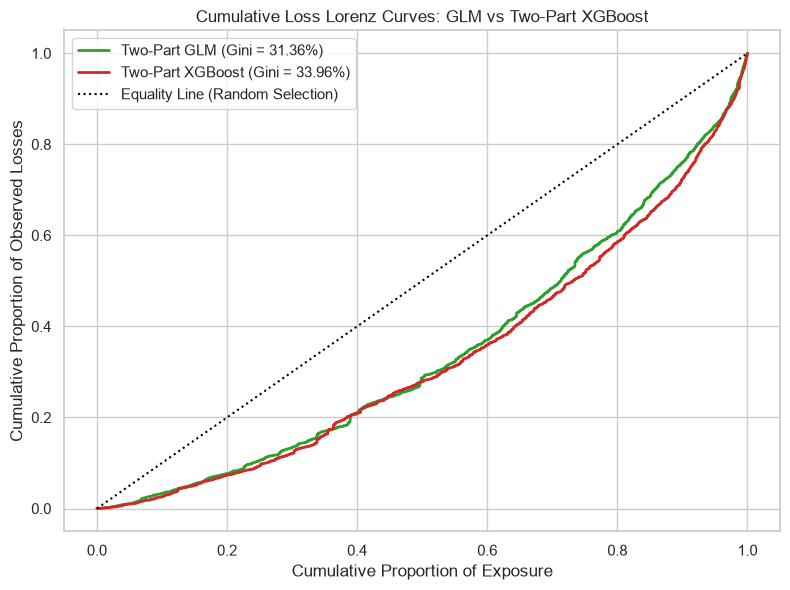

,Model Architecture,Test Gini Index,Gini Lift (pp),Relative Discrimination Lift
0,Two-Part GLM Baseline,31.36%,-,-
1,Two-Part XGBoost Champion,33.96%,+2.60 pp,+8.29%


In [3]:
# Compute Lorenz curves
cum_exp_glm, cum_loss_glm = compute_lorenz_curve(eval_df["PurePremium"], eval_df["Pred_GLM_Pure"], exposure=eval_df["Exposure_Capped"])
cum_exp_xgb, cum_loss_xgb = compute_lorenz_curve(eval_df["PurePremium"], eval_df["Pred_XGB_Pure"], exposure=eval_df["Exposure_Capped"])

gini_glm = gini_coefficient(eval_df["PurePremium"], eval_df["Pred_GLM_Pure"], exposure=eval_df["Exposure_Capped"])
gini_xgb = gini_coefficient(eval_df["PurePremium"], eval_df["Pred_XGB_Pure"], exposure=eval_df["Exposure_Capped"])

plt.figure(figsize=(8, 6))
plt.plot(cum_exp_glm, cum_loss_glm, color="#2ca02c", lw=2, label=f"Two-Part GLM (Gini = {gini_glm*100:.2f}%)")
plt.plot(cum_exp_xgb, cum_loss_xgb, color="#d62728", lw=2, label=f"Two-Part XGBoost (Gini = {gini_xgb*100:.2f}%)")
plt.plot([0, 1], [0, 1], color="black", linestyle=":", label="Equality Line (Random Selection)")
plt.title("Cumulative Loss Lorenz Curves: GLM vs Two-Part XGBoost", fontsize=12)
plt.xlabel("Cumulative Proportion of Exposure")
plt.ylabel("Cumulative Proportion of Observed Losses")
plt.legend(loc="upper left")
plt.tight_layout()
plt.show()

gini_df = pd.DataFrame({
    "Model Architecture": ["Two-Part GLM Baseline", "Two-Part XGBoost Champion"],
    "Test Gini Index": [f"{gini_glm*100:.2f}%", f"{gini_xgb*100:.2f}%"],
    "Gini Lift (pp)": ["-", f"+{(gini_xgb - gini_glm)*100:.2f} pp"],
    "Relative Discrimination Lift": ["-", f"+{(gini_xgb - gini_glm)/gini_glm*100:.2f}%"]
})
display(gini_df)

## 3. Double Lift Chart & Analysis

=== Decile Double Lift Table (XGBoost vs GLM) ===


,Bucket,Policies,Exposure,Avg_Ratio_Challenger_over_Baseline,Observed_Pure_Premium,Challenger_Pure_Premium,Baseline_Pure_Premium,Loss_Ratio_Challenger,Loss_Ratio_Baseline
0,1,13561,7229.756442,0.699609,138.300232,134.855155,202.832330,1.025546,0.681845
1,2,13560,8299.669563,0.805522,100.321423,101.199519,125.726666,0.991323,0.797933
2,3,13560,8274.545613,0.859294,95.244303,101.459394,118.096796,0.938743,0.806494
3,4,13560,7882.742101,0.909190,99.864592,105.045540,115.541382,0.950679,0.864319
4,5,13561,7428.150756,0.961684,108.515968,111.866138,116.323077,0.970052,0.932884
5,6,13560,7046.674455,1.019668,109.212250,119.415061,117.151320,0.914560,0.932232
6,7,13560,6634.808953,1.086291,112.919698,125.015957,115.143918,0.903242,0.980683
7,8,13561,6268.776328,1.167248,116.304939,133.742014,114.608695,0.869622,1.014800
8,9,13559,6104.805003,1.281141,149.049506,148.995532,116.218717,1.000362,1.282491
9,10,13561,6684.769436,1.655137,221.557918,208.935889,127.386066,1.060411,1.739263


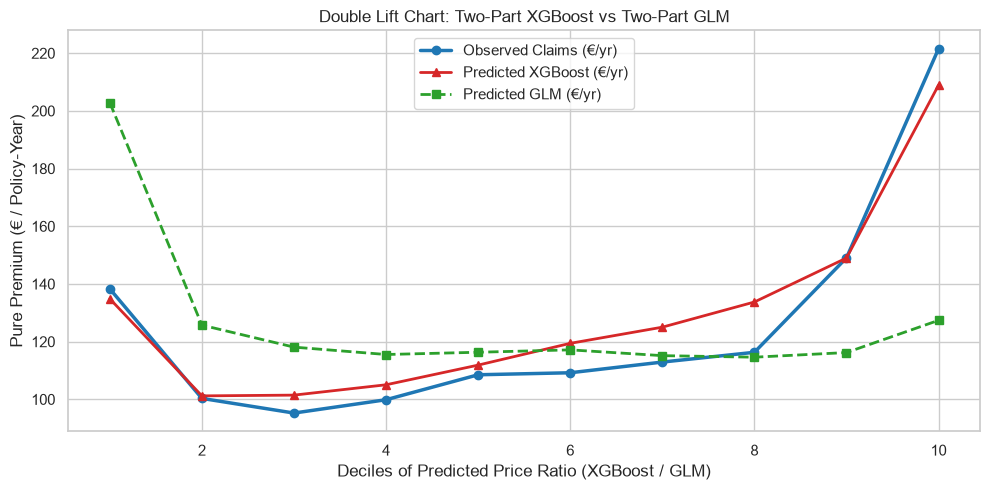

In [4]:
double_lift_df = compute_double_lift(
    eval_df,
    pred_challenger_col="Pred_XGB_Pure_Bal",
    pred_baseline_col="Pred_GLM_Pure_Bal",
    target_loss_col="AttritionalClaimAmount",
    exposure_col="Exposure_Capped",
    n_bins=BINS
)

print("=== Decile Double Lift Table (XGBoost vs GLM) ===")
display(double_lift_df)

# Plot Double Lift Chart
plt.figure(figsize=(10, 5))
plt.plot(double_lift_df["Bucket"], double_lift_df["Observed_Pure_Premium"], marker="o", color="#1f77b4", lw=2.5, label="Observed Claims (€/yr)")
plt.plot(double_lift_df["Bucket"], double_lift_df["Challenger_Pure_Premium"], marker="^", color="#d62728", lw=2, linestyle="-", label="Predicted XGBoost (€/yr)")
plt.plot(double_lift_df["Bucket"], double_lift_df["Baseline_Pure_Premium"], marker="s", color="#2ca02c", lw=2, linestyle="--", label="Predicted GLM (€/yr)")
plt.title("Double Lift Chart: Two-Part XGBoost vs Two-Part GLM", fontsize=12)
plt.xlabel("Deciles of Predicted Price Ratio (XGBoost / GLM)")
plt.ylabel("Pure Premium (€ / Policy-Year)")
plt.legend()
plt.tight_layout()
plt.show()

## 4. Decile Calibration & RMSCE Analysis

In [5]:
# Single-bucket calibration: bucket by GLM (baseline) so Observed + both Predicted share policies
eval_df["GLM_Decile"] = pd.qcut(eval_df["Pred_GLM_Pure"], q=K, labels=False, duplicates="drop") + 1

rows = []
for d in sorted(eval_df["GLM_Decile"].unique()):
    sub = eval_df[eval_df["GLM_Decile"] == d]
    exp = sub["Exposure_Capped"].sum()
    obs = sub["AttritionalClaimAmount"].sum() / exp if exp > 0 else 0.0
    glm_pred = np.average(sub["Pred_GLM_Pure_Bal"], weights=sub["Exposure_Capped"])
    xgb_pred = np.average(sub["Pred_XGB_Pure_Bal"], weights=sub["Exposure_Capped"])
    rows.append({
        "Decile": d,
        "Policies": len(sub),
        "Exposure": exp,
        "Observed_Pure_Premium": obs,
        "GLM_Predicted": glm_pred,
        "XGB_Predicted": xgb_pred,
        "GLM_Abs_Error": abs(obs - glm_pred),
        "XGB_Abs_Error": abs(obs - xgb_pred),
    })
calib_comparison_df = pd.DataFrame(rows)
w = calib_comparison_df["Exposure"] / calib_comparison_df["Exposure"].sum()
rmsce_glm = float(np.sqrt(np.sum(w * (calib_comparison_df["Observed_Pure_Premium"] - calib_comparison_df["GLM_Predicted"]) ** 2)))
rmsce_xgb = float(np.sqrt(np.sum(w * (calib_comparison_df["Observed_Pure_Premium"] - calib_comparison_df["XGB_Predicted"]) ** 2)))
print(f"=== Decile Calibration Table, common GLM buckets (GLM RMSCE: €{rmsce_glm:.2f} | XGBoost RMSCE: €{rmsce_xgb:.2f}) ===")
display(calib_comparison_df)

=== Decile Calibration Table, common GLM buckets (GLM RMSCE: €22.38 | XGBoost RMSCE: €16.56) ===


,Decile,Policies,Exposure,Observed_Pure_Premium,GLM_Predicted,XGB_Predicted,GLM_Abs_Error,XGB_Abs_Error
0,1,13561,8291.960236,40.641710,55.660885,60.096539,15.019175,19.454829
1,2,13560,7869.761287,56.089751,72.512009,75.667695,16.422258,19.577945
2,3,13560,7864.913214,73.990221,82.583499,84.605563,8.593278,10.615342
3,4,13560,7798.462248,98.119149,91.653359,92.792695,6.465790,5.326454
4,5,13561,7601.177461,95.042442,101.184500,101.799340,6.142058,6.756898
5,6,13560,7372.508078,136.082737,112.227828,114.186175,23.854909,21.896562
6,7,13560,6985.286990,159.234299,126.837379,131.063413,32.396920,28.170886
7,8,13560,6647.118270,148.460438,149.450349,157.358916,0.989911,8.898478
8,9,13560,6011.935795,191.215602,197.025656,203.547084,5.810054,12.331482
9,10,13561,5411.575069,323.901928,383.261744,340.997815,59.359816,17.095887
